# Motivation 4: battery loss power vs speed and CPU frequency

Battery loss power $P_b - P$ [W], where $P_b = \mathrm{OCV}\cdot I$ is the battery-side (cell) power for a constant load $P$ (2RC ECM, settled): the $R_0$ / RC losses, which grow as SOH falls. SOC fixed at 50 %, medium complexity.
(a) vs speed at a fixed CPU frequency (1.42 GHz); (b) vs DVFS level at a fixed speed (3 m/s).
Output: `figures/pdf/motivation_4.pdf`.

In [21]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import (ECMBattery, BatteryLimitError, ECMParams, motor_power, non_motor_power, CPU_FREQ_GHZ,
                            throughput_freq_required, quantize_freq)
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 15, 'axes.titlesize': 15, 'axes.labelsize': 15,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 15,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [22]:
ROBOT = make_robot(EVAL_CONFIG)
ECM = ECMParams.default(ROBOT)
SOC = 0.50                                   # SOC (fixed; only SOH is compared)
SOHS = [1.00, 0.90, 0.80]                    # state of health
C = 2.0                                      # medium workload complexity
F_FIX = 1.42                                 # (a) fixed CPU frequency [GHz]
V_FIX = 3.0                                  # (b) fixed speed [m/s]
SPEEDS = np.round(np.arange(1.0, ROBOT.v_max + 1e-9, 0.1), 2)
T_SETTLE = 600                               # s of constant load before reading (5 x the slow tau2 = 110 s)
QOS_MIN = max(ROBOT.qos_ref)
F_QOS = float(quantize_freq(throughput_freq_required(V_FIX, QOS_MIN, C)))   # min. QoS level at V_FIX
print(f'C = {C:g}, (a) f = {F_FIX} GHz, (b) v = {V_FIX} m/s, QoS needs >= {F_QOS:.2f} GHz at {V_FIX} m/s')

C = 2, (a) f = 1.42 GHz, (b) v = 3.0 m/s, QoS needs >= 0.96 GHz at 3.0 m/s


## Battery loss power

In [23]:
def battery_power(p_load, soc, soh):
    """Battery-side (cell) power OCV * I [W] for a constant load p_load [W] (2RC ECM, settled).
    Exceeds the load power by the R0 / RC losses, which grow as SOH falls."""
    b = ECMBattery(ECM, ROBOT, soc_init=soc, soh_init=soh)
    for _ in range(T_SETTLE):
        i, _, _ = b.step(p_load, dt=1.0)
    return i * b.ocv_v


P_LOAD_V = np.array([motor_power(v, 0.0, ROBOT) + non_motor_power(v, F_FIX, C, ROBOT) for v in SPEEDS])
P_LOAD_F = np.array([motor_power(V_FIX, 0.0, ROBOT) + non_motor_power(V_FIX, f, C, ROBOT)
                     for f in CPU_FREQ_GHZ])
LOSS_V = {h: np.array([battery_power(p, SOC, h) for p in P_LOAD_V]) - P_LOAD_V for h in SOHS}   # [W]
LOSS_F = {h: np.array([battery_power(p, SOC, h) for p in P_LOAD_F]) - P_LOAD_F for h in SOHS}
for h in SOHS:
    print(f'SOH {h:.2f}: loss at {SPEEDS[-1]:g} m/s = {LOSS_V[h][-1]:.3f} W, '
          f'at {CPU_FREQ_GHZ[-1]:.2f} GHz = {LOSS_F[h][-1]:.3f} W')

SOH 1.00: loss at 5 m/s = 0.559 W, at 2.04 GHz = 0.136 W
SOH 0.90: loss at 5 m/s = 0.858 W, at 2.04 GHz = 0.207 W
SOH 0.80: loss at 5 m/s = 1.169 W, at 2.04 GHz = 0.279 W


## Figure

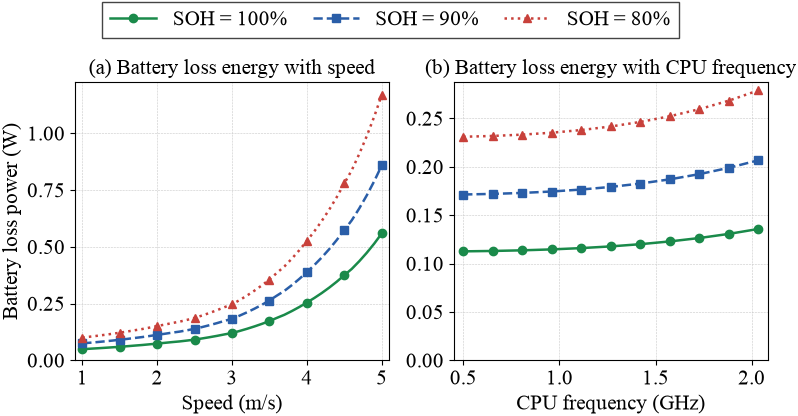

In [ ]:
# SOH: colour + line style + marker (distinguishable in greyscale)
SOH_STYLE = {1.00: dict(color='#1a8a4a', ls='-', marker='o'),
             0.90: dict(color='#2a5ea8', ls='--', marker='s'),
             0.80: dict(color='#c8413b', ls=':', marker='^')}
LW, MS = 1.8, 6
MARK_V = np.isclose(np.mod(SPEEDS + 1e-9, 0.5), 0.0, atol=1e-6)     # (a) markers every 0.5 m/s

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

ax = axes[0]
for h in SOHS:
    ax.plot(SPEEDS, LOSS_V[h], lw=LW, ms=MS, markevery=list(np.flatnonzero(MARK_V)), **SOH_STYLE[h])
ax.set_xlabel('Speed (m/s)')
ax.set_ylabel('Battery loss power (W)')
ax.set_title('(a) Battery loss energy with speed')
ax.set_xlim(SPEEDS[0] - 0.1, SPEEDS[-1] + 0.1)
ax.set_ylim(0, None)

ax = axes[1]
for h in SOHS:
    ax.plot(CPU_FREQ_GHZ, LOSS_F[h], lw=LW, ms=MS, **SOH_STYLE[h])
ax.set_xlabel('CPU frequency (GHz)')
ax.set_title('(b) Battery loss energy with CPU frequency')
ax.set_xlim(CPU_FREQ_GHZ[0] - 0.05, CPU_FREQ_GHZ[-1] + 0.05)
ax.set_xticks([0.5, 1.0, 1.5, 2.0])
ax.set_ylim(0, None)

handles = [Line2D([], [], lw=LW, ms=MS, label=f'SOH = {100 * h:.0f}%', **SOH_STYLE[h]) for h in SOHS]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.97), ncol=3, frameon=True,
           fancybox=False, edgecolor='#444444', framealpha=1.0, handlelength=2.2, columnspacing=1.2,
           borderpad=0.4)
fig.tight_layout(w_pad=0.8)
fig.savefig(OUT / 'motivation_4.pdf')
plt.show()